<a href="https://colab.research.google.com/github/Hideraldo/deteccao-fraude-cartao/blob/main/deteccao_fraudes_cartao_credito.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detecção de Fraudes em Cartões de Crédito

## Projeto de Machine Learning

**Objetivo:** Desenvolver modelos de Machine Learning capazes de identificar transações fraudulentas com cartões de crédito.

**Base de dados:** Credit Card Fraud Detection

**Tecnologias utilizadas:**
- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn
- XGBoost
- SHAP

**Métrica principal:** Recall da classe de fraude.

In [60]:

# Importação das bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração dos gráficos
sns.set_theme(style="whitegrid")

# Exibir todas as colunas
pd.set_option('display.max_columns', None)

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


In [61]:

# URL da base de dados
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

# Carregando os dados diretamente da internet
df = pd.read_csv(url)

# Mensagem de confirmação
print("Base de dados carregada com sucesso!")

Base de dados carregada com sucesso!


In [62]:

# Visualizar as primeiras 5 linhas
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [63]:

# Quantidade de linhas e colunas
print("Dimensões da base:", df.shape)

# Informações sobre as colunas
df.info()

Dimensões da base: (284807, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 n

In [64]:

# Quantidade de transações por classe
print("Quantidade de transações:")
print(df['Class'].value_counts())

print("\nProporção de cada classe:")
print(df['Class'].value_counts(normalize=True) * 100)

Quantidade de transações:
Class
0    284315
1       492
Name: count, dtype: int64

Proporção de cada classe:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


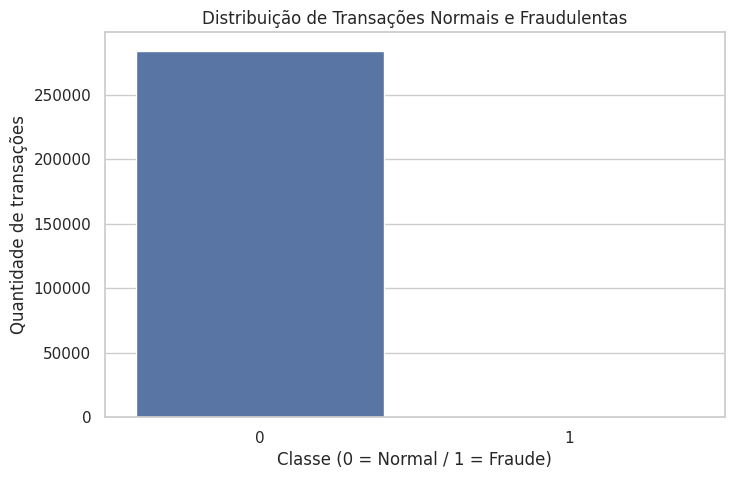

In [65]:

# Gráfico da distribuição das classes
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Class')

plt.title('Distribuição de Transações Normais e Fraudulentas')
plt.xlabel('Classe (0 = Normal / 1 = Fraude)')
plt.ylabel('Quantidade de transações')

plt.show()

In [66]:

# Criando uma cópia da base original
df_model = df.copy()

print("Cópia criada com sucesso!")
print("Dimensões:", df_model.shape)

Cópia criada com sucesso!
Dimensões: (284807, 31)


In [67]:

# Criando uma transformação logarítmica do valor
df_model['Amount'] = np.log1p(df_model['Amount'])

# Conferindo os valores
df_model[['Amount']].head()

,Amount
0,5.014760
1,1.305626
2,5.939276
3,4.824306
4,4.262539


In [68]:

# Separando as variáveis independentes e a variável alvo
X = df_model.drop('Class', axis=1)
y = df_model['Class']

print("Dimensões de X:", X.shape)
print("Dimensões de y:", y.shape)

Dimensões de X: (284807, 30)
Dimensões de y: (284807,)


In [69]:

from sklearn.model_selection import train_test_split

# Separando os dados em treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dados separados com sucesso!")
print("Treinamento:", X_train.shape)
print("Teste:", X_test.shape)

print("\nProporção de fraudes no treinamento:")
print(y_train.value_counts(normalize=True))

print("\nProporção de fraudes no teste:")
print(y_test.value_counts(normalize=True))

Dados separados com sucesso!
Treinamento: (227845, 30)
Teste: (56962, 30)

Proporção de fraudes no treinamento:
Class
0    0.998271
1    0.001729
Name: proportion, dtype: float64

Proporção de fraudes no teste:
Class
0    0.99828
1    0.00172
Name: proportion, dtype: float64


In [70]:

from sklearn.preprocessing import StandardScaler

# Criando o padronizador
scaler = StandardScaler()

# Ajustando e transformando os dados de treinamento
X_train_scaled = scaler.fit_transform(X_train)

# Transformando os dados de teste
X_test_scaled = scaler.transform(X_test)

print("Padronização realizada com sucesso!")

print("Treinamento:", X_train_scaled.shape)
print("Teste:", X_test_scaled.shape)

Padronização realizada com sucesso!
Treinamento: (227845, 30)
Teste: (56962, 30)


In [71]:

# Importando a Regressão Logística
from sklearn.linear_model import LogisticRegression

# Criando o modelo
modelo_logistico = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

# Treinando o modelo
modelo_logistico.fit(X_train_scaled, y_train)

print("Regressão Logística treinada com sucesso!")

Regressão Logística treinada com sucesso!


In [72]:

# Realizando previsões
y_pred_log = modelo_logistico.predict(X_test_scaled)

# Calculando probabilidades de fraude
y_prob_log = modelo_logistico.predict_proba(X_test_scaled)[:, 1]

print("Previsões realizadas com sucesso!")
print("Primeiras 10 previsões:")
print(y_pred_log[:10])

Previsões realizadas com sucesso!
Primeiras 10 previsões:
[0 0 0 0 1 0 0 0 0 0]


In [73]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score
)

print("RELATÓRIO DE CLASSIFICAÇÃO")
print(classification_report(y_test, y_pred_log))

print("Acurácia:", accuracy_score(y_test, y_pred_log))

print("ROC-AUC:", roc_auc_score(y_test, y_prob_log))

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

Acurácia: 0.9752291001018223
ROC-AUC: 0.9711170870993304


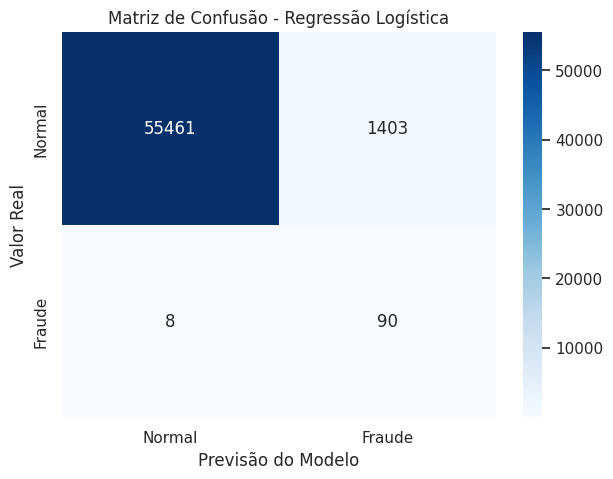

In [74]:

# Criando a matriz de confusão
cm = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Fraude'],
    yticklabels=['Normal', 'Fraude']
)

plt.title('Matriz de Confusão - Regressão Logística')
plt.xlabel('Previsão do Modelo')
plt.ylabel('Valor Real')

plt.show()

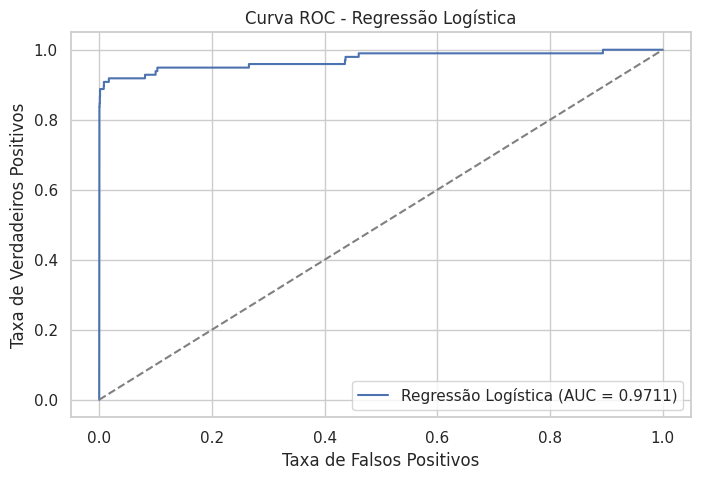

In [75]:

from sklearn.metrics import roc_curve, auc

# Calculando os pontos da curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob_log)

# Calculando a área sob a curva
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 5))

plt.plot(fpr, tpr, label=f'Regressão Logística (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.title('Curva ROC - Regressão Logística')
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')

plt.legend()
plt.show()

In [76]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Criando tabela de comparação
resultados = []

resultados.append({
    'Modelo': 'Regressão Logística',
    'Precisão': precision_score(y_test, y_pred_log),
    'Recall': recall_score(y_test, y_pred_log),
    'F1-score': f1_score(y_test, y_pred_log),
    'ROC-AUC': roc_auc_score(y_test, y_prob_log)
})

# Visualizar resultados
pd.DataFrame(resultados)

,Modelo,Precisão,Recall,F1-score,ROC-AUC
0,Regressão Logística,0.060281,0.918367,0.113136,0.971117


In [77]:

from sklearn.ensemble import RandomForestClassifier

# Criando o modelo Random Forest
modelo_rf = RandomForestClassifier(
    n_estimators=150,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

print("Random Forest criado com sucesso!")

Random Forest criado com sucesso!


In [78]:

# Treinando o Random Forest
modelo_rf.fit(X_train, y_train)

print("Random Forest treinado com sucesso!")

Random Forest treinado com sucesso!


In [79]:

# Previsões do Random Forest
y_pred_rf = modelo_rf.predict(X_test)

# Probabilidades de fraude
y_prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

print("Previsões realizadas com sucesso!")

Previsões realizadas com sucesso!


In [80]:

print("RELATÓRIO RANDOM FOREST")
print(classification_report(y_test, y_pred_rf))

print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

RELATÓRIO RANDOM FOREST
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.96      0.76      0.85        98

    accuracy                           1.00     56962
   macro avg       0.98      0.88      0.92     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC: 0.9575686492942702


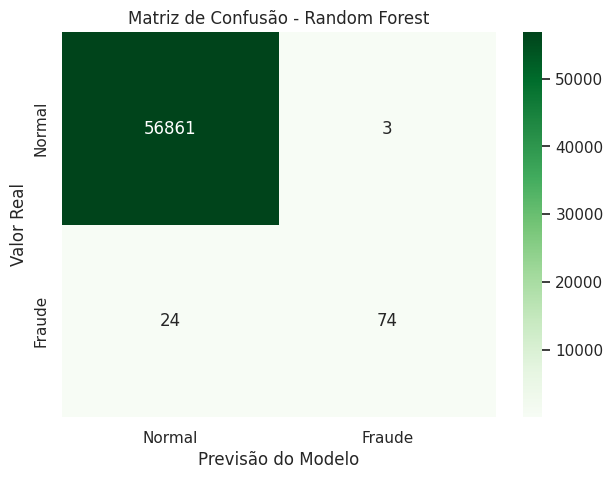

In [81]:

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Normal', 'Fraude'],
    yticklabels=['Normal', 'Fraude']
)

plt.title('Matriz de Confusão - Random Forest')
plt.xlabel('Previsão do Modelo')
plt.ylabel('Valor Real')

plt.show()

In [82]:

resultados.append({
    'Modelo': 'Random Forest',
    'Precisão': precision_score(y_test, y_pred_rf),
    'Recall': recall_score(y_test, y_pred_rf),
    'F1-score': f1_score(y_test, y_pred_rf),
    'ROC-AUC': roc_auc_score(y_test, y_prob_rf)
})

# Comparar os modelos
pd.DataFrame(resultados).round(4)

,Modelo,Precisão,Recall,F1-score,ROC-AUC
0,Regressão Logística,0.0603,0.9184,0.1131,0.9711
1,Random Forest,0.9610,0.7551,0.8457,0.9576


In [83]:
from xgboost import XGBClassifier

# scale_pos_weight = nº de normais / nº de fraudes
# É o equivalente do class_weight='balanced': dá mais peso à classe rara (fraude)
peso_fraude = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Peso aplicado à fraude: {peso_fraude:.1f}")

# Criando o modelo XGBoost
modelo_xgb = XGBClassifier(
    n_estimators=300,            # número de árvores
    max_depth=5,                 # profundidade máxima de cada árvore
    learning_rate=0.1,           # quanto cada árvore corrige a anterior
    scale_pos_weight=peso_fraude,
    eval_metric='aucpr',         # métrica interna: área sob a curva precisão x recall
    random_state=42,
    n_jobs=-1
)

# Treinando apenas com os dados de treino
modelo_xgb.fit(X_train, y_train)

print("XGBoost treinado com sucesso!")

Peso aplicado à fraude: 577.3
XGBoost treinado com sucesso!


RELATÓRIO XGBOOST
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.87      0.84      0.85        98

    accuracy                           1.00     56962
   macro avg       0.94      0.92      0.93     56962
weighted avg       1.00      1.00      1.00     56962



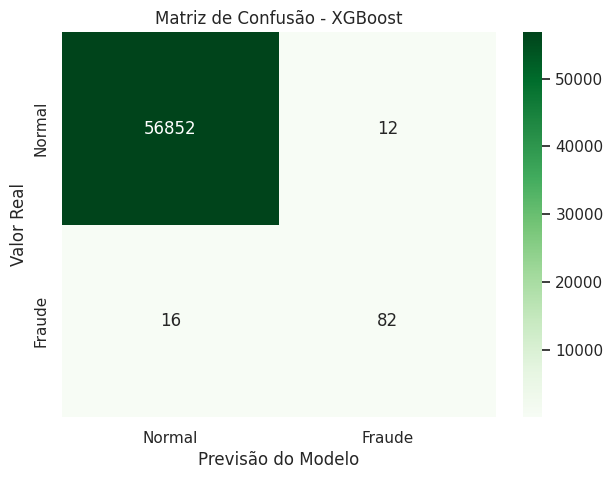

In [84]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Previsão de classe (0 ou 1) e probabilidade de ser fraude
y_pred_xgb = modelo_xgb.predict(X_test)
y_proba_xgb = modelo_xgb.predict_proba(X_test)[:, 1]

print("RELATÓRIO XGBOOST")
print(classification_report(y_test, y_pred_xgb))

# Matriz de confusão: mostra acertos e erros de cada tipo
cm = confusion_matrix(y_test, y_pred_xgb)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Normal', 'Fraude'],
            yticklabels=['Normal', 'Fraude'])
plt.title('Matriz de Confusão - XGBoost')
plt.xlabel('Previsão do Modelo')
plt.ylabel('Valor Real')
plt.show()

In [85]:
# Guardando as previsões de todos os modelos para comparar depois
y_pred_lr = modelo_lr.predict(X_test)
y_proba_lr = modelo_lr.predict_proba(X_test)[:, 1]

y_pred_rf = modelo_rf.predict(X_test)
y_proba_rf = modelo_rf.predict_proba(X_test)[:, 1]

# Dicionário: nome do modelo -> probabilidades de fraude
probabilidades = {
    'Regressão Logística': y_proba_lr,
    'Random Forest': y_proba_rf,
    'XGBoost': y_proba_xgb,
}

print("Previsões organizadas para:", list(probabilidades.keys()))

Previsões organizadas para: ['Regressão Logística', 'Random Forest', 'XGBoost']


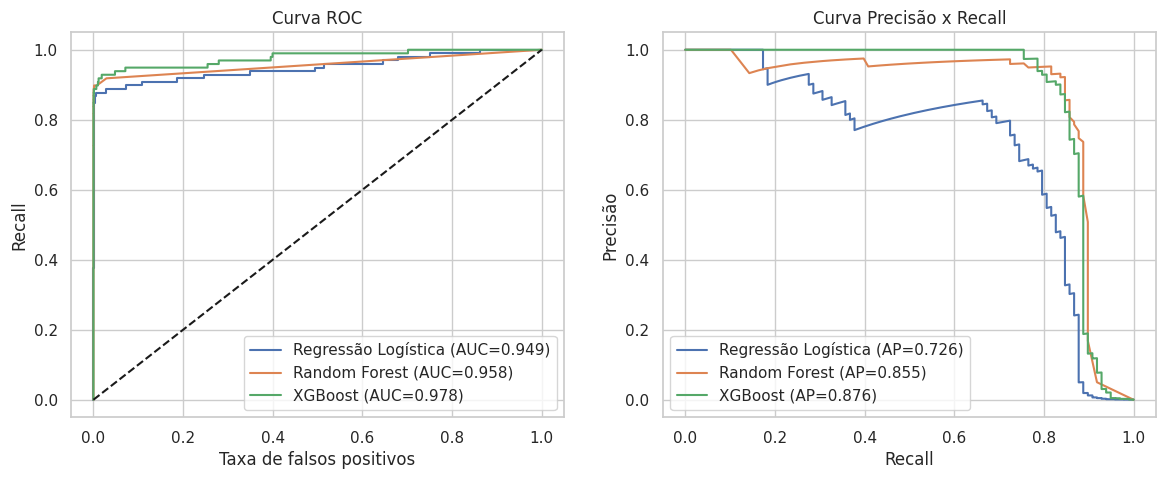

In [86]:
from sklearn.metrics import (roc_curve, precision_recall_curve,
                             roc_auc_score, average_precision_score)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for nome, proba in probabilidades.items():
    # Curva ROC: taxa de fraudes achadas vs taxa de alarmes falsos
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax[0].plot(fpr, tpr, label=f'{nome} (AUC={roc_auc_score(y_test, proba):.3f})')

    # Curva Precisão x Recall: a mais útil em dados desbalanceados
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ax[1].plot(rec, prec, label=f'{nome} (AP={average_precision_score(y_test, proba):.3f})')

# Linha tracejada = modelo que chuta aleatoriamente
ax[0].plot([0, 1], [0, 1], 'k--')
ax[0].set(title='Curva ROC', xlabel='Taxa de falsos positivos', ylabel='Recall')
ax[1].set(title='Curva Precisão x Recall', xlabel='Recall', ylabel='Precisão')
ax[0].legend()
ax[1].legend()
plt.show()

In [87]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Função que calcula as métricas da classe de fraude (classe 1)
def calcular_metricas(nome, y_true, y_pred, y_proba):
    return {
        'Modelo': nome,
        'Precisão': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_proba),
        'PR-AUC': average_precision_score(y_true, y_proba),
    }

tabela_modelos = pd.DataFrame([
    calcular_metricas('Regressão Logística', y_test, y_pred_lr, y_proba_lr),
    calcular_metricas('Random Forest', y_test, y_pred_rf, y_proba_rf),
    calcular_metricas('XGBoost', y_test, y_pred_xgb, y_proba_xgb),
]).round(4)

tabela_modelos

,Modelo,Precisão,Recall,F1,ROC-AUC,PR-AUC
0,Regressão Logística,0.8095,0.6939,0.7473,0.9493,0.7257
1,Random Forest,0.9610,0.7551,0.8457,0.9576,0.8555
2,XGBoost,0.8723,0.8367,0.8542,0.9775,0.8760


In [88]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Pipeline junta padronização + modelo em um único objeto
# Vantagem: o scaler é ajustado SÓ no treino, evitando vazamento de dados do teste
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('modelo', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

pipe_lr.fit(X_train, y_train)
print("Pipeline da Regressão Logística treinado!")

Pipeline da Regressão Logística treinado!


In [89]:
# Função que testa vários limiares e mostra o efeito em precisão, recall e F1
def testar_limiares(modelo, X, y, limiares=(0.1, 0.3, 0.5, 0.7, 0.9)):
    proba = modelo.predict_proba(X)[:, 1]
    linhas = []
    for limiar in limiares:
        # Marca como fraude se a probabilidade for >= limiar
        pred = (proba >= limiar).astype(int)
        linhas.append({
            'Limiar': limiar,
            'Precisão': precision_score(y, pred, zero_division=0),
            'Recall': recall_score(y, pred),
            'F1': f1_score(y, pred),
            'Fraudes detectadas': int(((pred == 1) & (y == 1)).sum()),
            'Falsos alarmes': int(((pred == 1) & (y == 0)).sum()),
        })
    return pd.DataFrame(linhas).round(4)

print("Regressão Logística:")
display(testar_limiares(pipe_lr, X_test, y_test))

Regressão Logística:


,Limiar,Precisão,Recall,F1,Fraudes detectadas,Falsos alarmes
0,0.1,0.0080,0.9490,0.0158,93,11553
1,0.3,0.0262,0.9184,0.0510,90,3342
2,0.5,0.0603,0.9184,0.1131,90,1403
3,0.7,0.1208,0.9082,0.2132,89,648
4,0.9,0.2486,0.8878,0.3884,87,263


In [90]:
# O mesmo teste aplicado ao Random Forest (ideia de evolução do desafio)
pipe_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('modelo', RandomForestClassifier(
        n_estimators=150, class_weight='balanced', random_state=42, n_jobs=-1))
])

pipe_rf.fit(X_train, y_train)

print("Random Forest em Pipeline:")
display(testar_limiares(pipe_rf, X_test, y_test, limiares=(0.1, 0.2, 0.3, 0.4, 0.5)))

Random Forest em Pipeline:


,Limiar,Precisão,Recall,F1,Fraudes detectadas,Falsos alarmes
0,0.1,0.7478,0.8776,0.8075,86,29
1,0.2,0.8557,0.8469,0.8513,83,14
2,0.3,0.9213,0.8367,0.8770,82,7
3,0.4,0.9512,0.7959,0.8667,78,4
4,0.5,0.9610,0.7551,0.8457,74,3


In [92]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Amostra para a busca: mantém TODAS as fraudes do treino + 40 mil normais
# A busca só precisa comparar configurações; o modelo final pode usar todos os dados
idx_fraude = y_train[y_train == 1].index
idx_normal = y_train[y_train == 0].sample(40000, random_state=42).index
idx_busca = idx_fraude.union(idx_normal)

X_busca = X_train.loc[idx_busca]
y_busca = y_train.loc[idx_busca]
print("Tamanho da amostra de busca:", X_busca.shape, "| fraudes:", y_busca.sum())

# Grade reduzida: 4 combinações x 3 divisões = 12 treinos
grade = {
    'modelo__n_estimators': [100],
    'modelo__max_depth': [10, 20],
    'modelo__min_samples_leaf': [1, 3],
}

busca = GridSearchCV(
    estimator=pipe_rf,
    param_grid=grade,
    scoring='recall',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),  # mantém a proporção de fraudes em cada divisão
    n_jobs=-1,
    verbose=2
)

busca.fit(X_busca, y_busca)

print("Melhores parâmetros:", busca.best_params_)
print(f"Melhor recall na validação: {busca.best_score_:.4f}")

Tamanho da amostra de busca: (40394, 30) | fraudes: 394
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Melhores parâmetros: {'modelo__max_depth': 10, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 100}
Melhor recall na validação: 0.8172


In [93]:
from sklearn.base import clone

# Recria o pipeline com os melhores parâmetros e treina com TODO o conjunto de treino
melhor_modelo = clone(pipe_rf).set_params(**busca.best_params_)
melhor_modelo.fit(X_train, y_train)

y_pred_grid = melhor_modelo.predict(X_test)
y_proba_grid = melhor_modelo.predict_proba(X_test)[:, 1]

print("RELATÓRIO - RANDOM FOREST AJUSTADO")
print(classification_report(y_test, y_pred_grid))
print(f"PR-AUC: {average_precision_score(y_test, y_proba_grid):.4f}")

RELATÓRIO - RANDOM FOREST AJUSTADO
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.79      0.83      0.81        98

    accuracy                           1.00     56962
   macro avg       0.89      0.91      0.90     56962
weighted avg       1.00      1.00      1.00     56962

PR-AUC: 0.8280


In [94]:
melhor_modelo = busca.best_estimator_

y_pred_grid = melhor_modelo.predict(X_test)
y_proba_grid = melhor_modelo.predict_proba(X_test)[:, 1]

print("RELATÓRIO - RANDOM FOREST AJUSTADO")
print(classification_report(y_test, y_pred_grid))
print(f"PR-AUC: {average_precision_score(y_test, y_proba_grid):.4f}")

RELATÓRIO - RANDOM FOREST AJUSTADO
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.76      0.86      0.80        98

    accuracy                           1.00     56962
   macro avg       0.88      0.93      0.90     56962
weighted avg       1.00      1.00      1.00     56962

PR-AUC: 0.8041


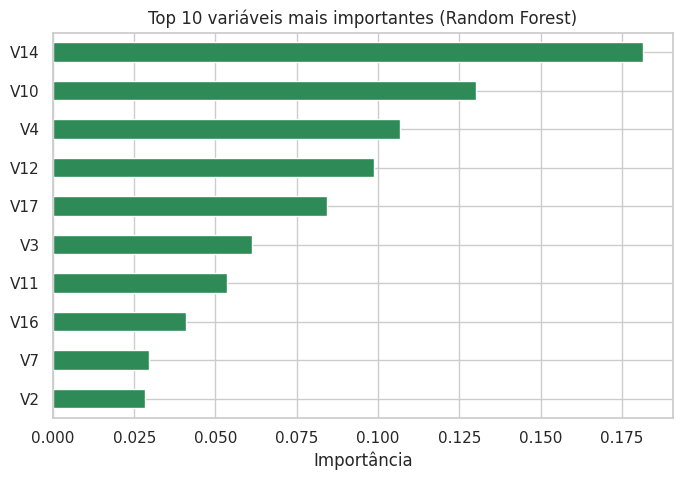

In [95]:
# Importância segundo o Random Forest: quanto cada variável ajudou a separar fraude de normal
importancias = pd.Series(
    modelo_rf.feature_importances_, index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importancias.head(10).sort_values().plot(kind='barh', color='seagreen')
plt.title('Top 10 variáveis mais importantes (Random Forest)')
plt.xlabel('Importância')
plt.show()

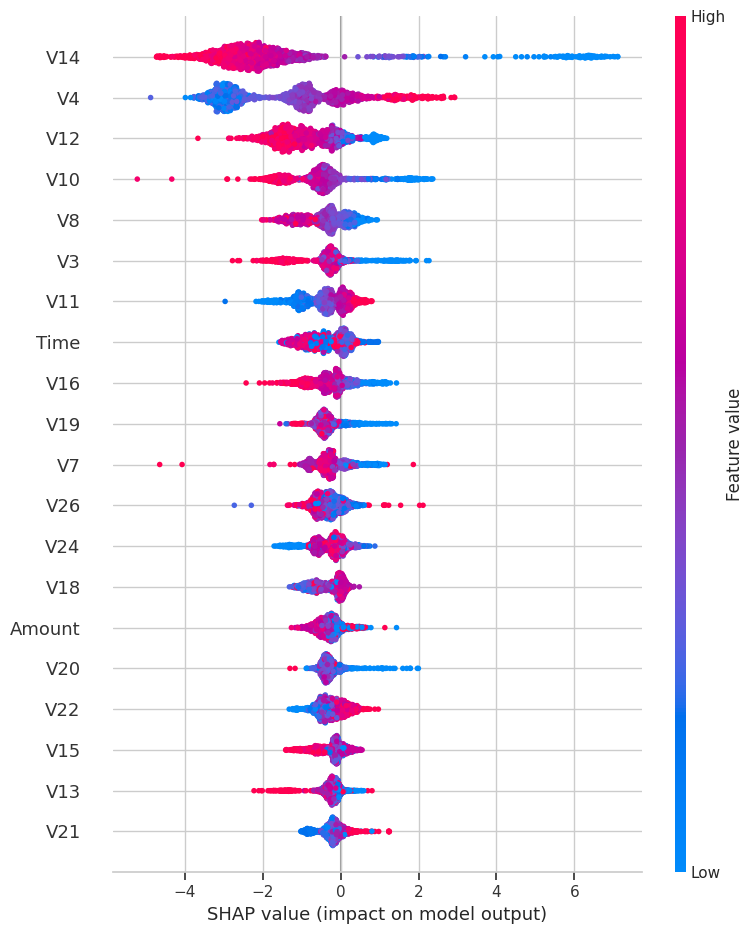

In [96]:
import shap

# Amostra com TODAS as fraudes do teste + 1500 transações normais (SHAP em tudo seria lento)
amostra = pd.concat([
    X_test[y_test == 1],
    X_test[y_test == 0].sample(1500, random_state=42)
])

# TreeExplainer é o explicador rápido para modelos de árvores
explainer = shap.TreeExplainer(modelo_xgb)
shap_values = explainer(amostra)

# Gráfico geral: cada ponto é uma transação; mostra quais variáveis mais pesam
shap.summary_plot(shap_values, amostra)

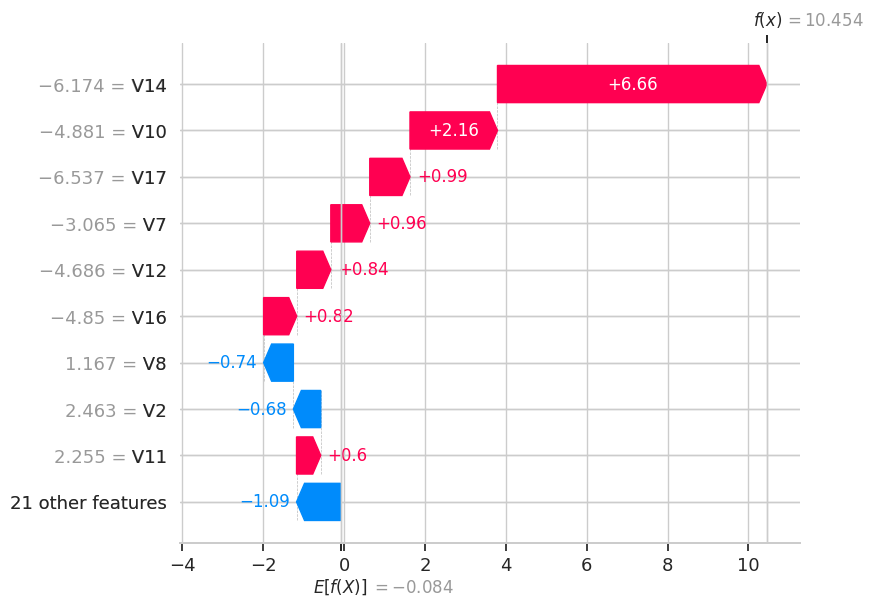

In [97]:
# Pega a posição da primeira fraude real dentro da amostra
posicao_fraude = list(amostra.index).index(X_test[y_test == 1].index[0])

# Waterfall: mostra como cada variável empurrou a decisão (vermelho = rumo à fraude)
shap.plots.waterfall(shap_values[posicao_fraude])

In [98]:
# !pip install imbalanced-learn   # descomente se necessário
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Oversampling: cria fraudes sintéticas | Undersampling: remove transações normais
# IMPORTANTE: só o TREINO é reamostrado; o teste continua intacto
X_over, y_over = SMOTE(random_state=42).fit_resample(X_train, y_train)
X_under, y_under = RandomUnderSampler(random_state=42).fit_resample(X_train, y_train)

print("Original:", y_train.value_counts().to_dict())
print("SMOTE:", y_over.value_counts().to_dict())
print("Undersampling:", y_under.value_counts().to_dict())

Original: {0: 227451, 1: 394}
SMOTE: {0: 227451, 1: 227451}
Undersampling: {0: 394, 1: 394}


In [104]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Oversampling: cria fraudes sintéticas | Undersampling: remove transações normais
# IMPORTANTE: só o TREINO é reamostrado; o teste continua intacto
X_over, y_over = SMOTE(random_state=42).fit_resample(X_train, y_train)
X_under, y_under = RandomUnderSampler(random_state=42).fit_resample(X_train, y_train)

print("Original:", y_train.value_counts().to_dict())
print("SMOTE:", y_over.value_counts().to_dict())
print("Undersampling:", y_under.value_counts().to_dict())

Original: {0: 227451, 1: 394}
SMOTE: {0: 227451, 1: 227451}
Undersampling: {0: 394, 1: 394}


In [105]:
# Treina o mesmo Random Forest em cada versão e compara na MESMA base de teste
resultados = []
for nome, (Xr, yr) in {'SMOTE': (X_over, y_over),
                       'Undersampling': (X_under, y_under)}.items():
    rf = RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1)
    rf.fit(Xr, yr)
    pred = rf.predict(X_test)
    resultados.append({
        'Estratégia': nome,
        'Precisão': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'Fraudes detectadas': int(((pred == 1) & (y_test == 1)).sum()),
        'Falsos alarmes': int(((pred == 1) & (y_test == 0)).sum()),
    })

pd.DataFrame(resultados).round(4)

,Estratégia,Precisão,Recall,F1,Fraudes detectadas,Falsos alarmes
0,SMOTE,0.8351,0.8265,0.8308,81,16
1,Undersampling,0.0414,0.9082,0.0792,89,2061


In [106]:
# Confere qual modelo está guardado em melhor_modelo e seu desempenho no teste
print("Parâmetros:", melhor_modelo.get_params()['modelo'])

y_pred_conf = melhor_modelo.predict(X_test)
y_proba_conf = melhor_modelo.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred_conf))
print(f"PR-AUC: {average_precision_score(y_test, y_proba_conf):.4f}")

Parâmetros: RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_leaf=3, n_jobs=-1, random_state=42)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.76      0.86      0.80        98

    accuracy                           1.00     56962
   macro avg       0.88      0.93      0.90     56962
weighted avg       1.00      1.00      1.00     56962

PR-AUC: 0.8041
